In [1]:

using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

In [2]:
@pyimport wandb
wandb.login(key="04a3943a16046e23c3b1a946c43cfb657e4b1f8d")


wandb: Currently logged in as: nmt121 (natmtc). Use `wandb login --relogin` to force relogin
wandb: Appending key for api.wandb.ai to your netrc file: /Users/nmt121/.netrc


true

## MN parameters 

#### All types of motoneurons merged

In [2]:
######################  ALL TYPES #######################
#########################################################
nr_s = 10

division_nr_s= trunc(Int, nr_s/3)+1#three types of motoneurons (S-type, FR-type and FF-type)


# Radius and soma lengths

rheobase_S = vcat(LinRange(3.5,6.5,division_nr_s), LinRange(6.5,17.5,division_nr_s), LinRange(17.5,25.10 ,nr_s - division_nr_s*2))
rs_S = vcat(LinRange(38.75,41.25,division_nr_s), LinRange(41.25,43.75,division_nr_s), LinRange(43.75,56.50 ,nr_s - division_nr_s*2))./10000
ls_S = vcat(LinRange(77.50,82.50,division_nr_s), LinRange(82.50,87.50,division_nr_s), LinRange(87.5,113.0 ,nr_s - division_nr_s*2))./10000
rms_S = vcat(LinRange(1.15,1.05,division_nr_s), LinRange(1.05,0.95,division_nr_s), LinRange(0.95,0.65 ,nr_s - division_nr_s*2)).*1000
rd_S = vcat(LinRange(20.75,31.25,division_nr_s), LinRange(31.25,41.75,division_nr_s), LinRange(41.75,46.25,nr_s - division_nr_s*2))./10000
ld_S = vcat(LinRange(5500.,6800.,division_nr_s), LinRange(6800.,8100.,division_nr_s), LinRange(8100,10600,nr_s - division_nr_s*2))./10000
rmd_S = vcat(LinRange(14.4,10.70,division_nr_s), LinRange(10.7,6.95,division_nr_s), LinRange(6.95,6.05,nr_s - division_nr_s*2)).*1000


#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S =  vcat(ones(division_nr_s)*4, LinRange(4.,2.25,division_nr_s), LinRange(2.25,0.5 ,nr_s - division_nr_s*2))
max_gks_S = vcat(LinRange(16.,25.,division_nr_s), LinRange(25.,19.,division_nr_s), LinRange(19.,4. ,nr_s - division_nr_s*2))
max_gca_S =  vcat(LinRange(0.038,0.029,division_nr_s), LinRange(0.029,0.016,division_nr_s), LinRange(0.016,0.012 ,nr_s - division_nr_s*2))

# Rate constants of the kinetic processes in ms^-1
αm = 22.0
βm = 13.0
αh_S = vcat(ones(division_nr_s)*0.5, LinRange(0.5,11.25,division_nr_s), LinRange(11.25,22.,nr_s - division_nr_s*2))
βh_S = vcat(ones(division_nr_s)*4., LinRange(4.,13.,division_nr_s), LinRange(13.,22.,nr_s - division_nr_s*2))
αn_S = vcat(ones(division_nr_s)*1.5, LinRange(1.5,11.75,division_nr_s), LinRange(11.75,22.,nr_s - division_nr_s*2))
βn_S = vcat(ones(division_nr_s)*0.1, LinRange(0.1,11.05,division_nr_s), LinRange(11.05,22.,nr_s - division_nr_s*2))
αq_S = vcat(ones(division_nr_s)*1.5, LinRange(1.5,11.75,division_nr_s), LinRange(11.75,22.,nr_s - division_nr_s*2))
βq_S = vcat(LinRange(0.025,0.038,division_nr_s), LinRange(0.038,11.025,division_nr_s), LinRange(11.025,22.,nr_s - division_nr_s*2))
αp = 0.008
βp= vcat(LinRange(0.014,0.016,division_nr_s), LinRange(0.016,0.019,division_nr_s), LinRange(0.019,0.020,nr_s - division_nr_s*2))
βp_S = vcat(LinRange(0.014,0.016,division_nr_s), LinRange(0.016,0.019,division_nr_s), LinRange(0.019,0.020,nr_s - division_nr_s*2))

Vthca_S = vcat(LinRange(2.5,3.,division_nr_s), LinRange(3.,8.,division_nr_s), LinRange(8,8.5,nr_s - division_nr_s*2)) # .+ rand(Normal(0.0,0.028),nr_s) # voltage threshold to Ca conductance
Apeak_S = vcat(LinRange(0.103,0.123,division_nr_s), LinRange(0.123,0.294,division_nr_s), LinRange(0.294,0.491,nr_s - division_nr_s*2)) #peak twitch amplitude in Newton (related to the strength of the response)
tpeak_S = vcat(LinRange(110.0,100.,division_nr_s), LinRange(73.5,55.5,division_nr_s), LinRange(82.3,56.9,nr_s - division_nr_s*2)) #time to peak in ms
tetanic_S = LinRange(0.393,0.491,nr_s);# tetanic force in Newton (max force that a muscle can produce when it's stimulated very rapidly)

#EXCITATORY PROFILE
amplitude=0.6
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

# EF= LinRange(0.8,1.8, nr_s);

#HYSTERESIS

x_values = LinRange(-1, 1, nr_s)
A = 1.5  # amplitude of the exp
k= 10.0  # control rate ramp up and ramp down
γh = zeros(nr_s);
for i in 1:nr_s
    x = x_values[i]
    if x < 0
        γh[i] = A * exp(k * x)
    else 
        γh[i] = A * exp(-k * x)
    end

end
# γh= γh .+ 0.05;

γh = ones(nr_s);


EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 #reversal potentials
Ge=0.6; Gi=0.5 ; #maximun conductances
Vd0 = 0.; Vs0 = 0.;#initial voltages
rp=5.0; #refractory period
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]




#### Slow-type motoneurons

In [2]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = 22.0; βm = 13.0
αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4
αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1
αq_S = ones(nr_s)*1.5
βq_S = ones(nr_s)*0.025
αp = 0.008
βp= LinRange(0.014,0.016,nr_s)
βp_S = ones(nr_s)*0.014

Vthca_S = LinRange(2.5,3.0,nr_s) 
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion
# EF= LinRange(0.8,1.8, nr_s);


γh = zeros(nr_s);
# γh = [0.,0.,0.,0.12348,0.,0.,0.0902577,0.057332,0.,0.0491277]; #optimised values, test
# γh = [0.05006809989464373,0.05062841318517258,0.05579888020920921,0.10351099002087855,0.5433042529655824, 0.5444886490103167,0.13541465860474394,0.055798880209209215,0.061345798467742504,0.05006809989464373]
#reversal potentials
EL=0; 
ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 
#maximun conductances
Ge=0.6; Gi=0.5 ; 
#initial voltages
Vd0 = 0.; 
Vs0 = 0.;
#refractory period
rp=5.0; 
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]




In [2]:
######################  S-TYPE ##########################
#########################################################
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/regressed_parameter_87neurons_NOIF.jld2" regressed_parameter
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hystprofile.jld2" γn_new

nr_s = 87

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = regressed_parameter[1,:]
ls_S = regressed_parameter[2,:] 
rms_S = regressed_parameter[3,:]
rd_S = regressed_parameter[4,:]
ld_S = regressed_parameter[5,:]
rmd_S = regressed_parameter[6,:]

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S = regressed_parameter[7,:]
max_gca_S = regressed_parameter[8,:]


# Rate constants of the kinetic processes in ms^-1
αm = 22.0; βm = 13.0
αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4
αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1
αq_S = ones(nr_s)*1.5
βq_S = ones(nr_s)*0.025
αp = 0.008
βp= regressed_parameter[9,:]
βp_S = ones(nr_s)*0.014

Vthca_S = regressed_parameter[10,:]
Apeak_S =  regressed_parameter[11,:]
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

### remove these 2 in the future
#AMPLIFICATION
γa=1.;
#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; 
ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 
#maximun conductances
Ge=0.6; Gi=0.5 ; 
#initial voltages
Vd0 = 0.; 
Vs0 = 0.;
#refractory period
rp=5.0; 
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]


### New distribution of hysteresis profile (eta) after running optim

In [3]:
x_values = LinRange(0, 87, nr_s);
γh= γn_new[1,:];
# Plots.scatter(x_values, γh, xlabel="x", ylabel="γh", title="Hysteresis profile",grid=false,legend=false)

87-element Vector{Float64}:
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.04348670567975481
 0.0
 0.20619781695415837
 0.07278618949625648
 0.1057888242135507
 0.0
 0.0057940263089950594
 0.08499459489112432
 0.46594678151027424

### MN parameters we need to fill with previous data (and creation of the dictionary)

In [4]:
ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp, :βp => βp_S[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm, :βm => βm, :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i],:αp => αp, :βp => βp[i],  :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;

### Running simulation

In [5]:
tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function

In [6]:
function run_sim_optim_constant_inh()
    for i in 1:nr_s
        # temp = filter_input(50,rand(Normal(0, 1),sim_length+2000))  # add some gaussian noise - optional
        # independantnoise[i,:] = temp[1001:end-1000] * 0.25;
        full_input[i,:] = commoninput  + independantnoise[i,:]; 
        vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input[i,:], inh_input, MNs)      
        spikes = spikes_from_aps(vs, i, MNs)       
        spike_arr[i,:] = spikes
        vs_arr[i,:] = vs
    end
    return spike_arr, vs_arr
end

run_sim_optim_constant_inh (generic function with 1 method)

In [7]:
full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.3 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);

# tr=tr_new
# @time spike_array, vs_array = run_sim();

@time spike_array, vs_array = run_sim_optim_constant_inh();

# JLD2.@save "DR_23Apr.jld2" spike_array
# JLD2.@load "DR_070224.jld2" spike_array

244.837908 seconds (15.74 G allocations: 260.750 GiB, 4.57% gc time, 0.02% compilation time)


([0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [0.0 -0.0031792231339897565 … -7.964046533478188 -7.964046533478188; 0.0 -0.0031775344891977093 … -7.931809011836636 -7.931809011836636; … ; 0.0 -0.0027512649763944555 … -3.993526040403472 -3.993526040403472; 0.0 -0.0027372818167245476 … -3.915645334579033 -3.915645334579033])

In [40]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_87Neurons_optim_I0.3_LAST.jld2" spike_array

In [30]:
# Plots.plot(vs_array[2,:]) #to plot the voltage as they do in old papers

##### Plotting with the excitatory input all together to compare

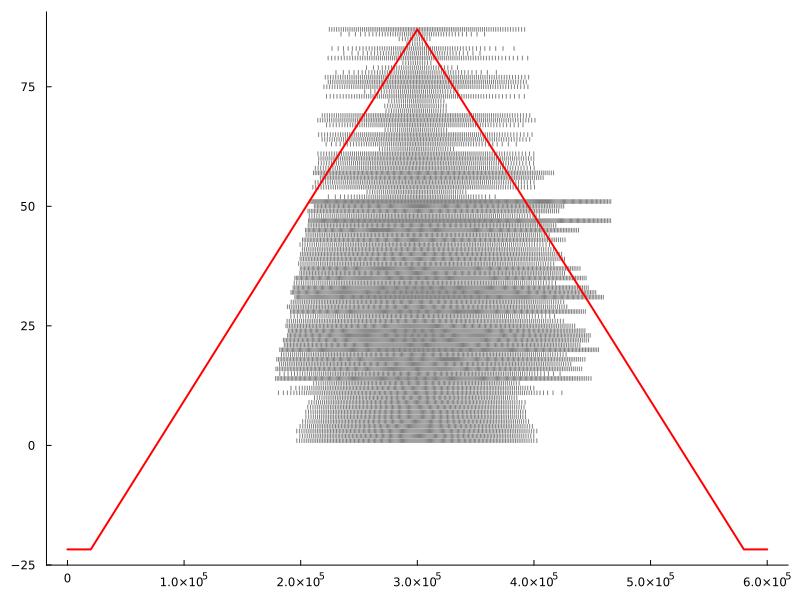

In [9]:
amplitude=0.4;
sim_length=560000 ;

half_triang = div(sim_length, 2);  # Half the total length minus plateau length, rounding down if necessary
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);


spike_times = []
neuron_ids = []
for i in 1:size(spike_array, 1)
    spikes = findall(spike_array[i, :] .== 1) #when the MNs fires 
    for t in spikes
        push!(spike_times, [t, t])
        push!(neuron_ids, [i - 0.4, i + 0.4])
    end
end

Plots.plot(spike_times, neuron_ids, line=(1), legend=false, color =:gray,size=(800, 600),grid = false)
Plots.plot!((tr/maximum(tr))*nr_s,line=(2), color =:red,grid = false)
# xlabel!()
# ylabel()


##### Faster way to plot for a Raster Visualitation

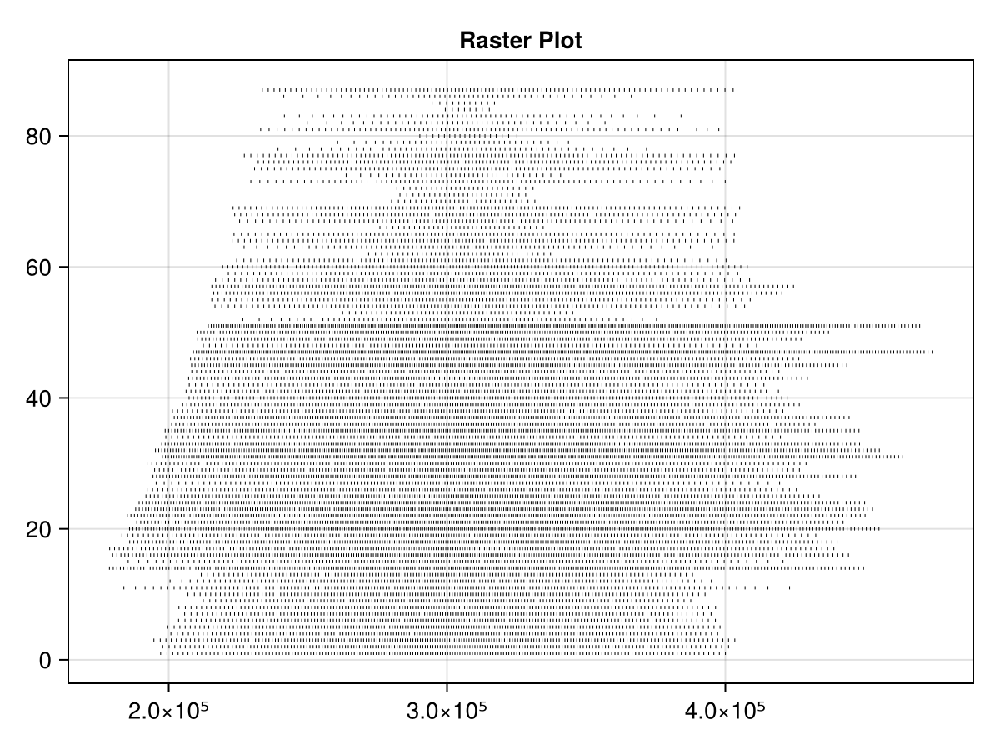

CairoMakie.Screen{IMAGE}


In [8]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = CairoMakie.Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
        end
    end
end

# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


## W&B - Hyperparameter sweep to explore the whole range of possible values

#### at some points add these functions outside here 

In [15]:

function simulate_hh_hysteresis_constant_inh(γh::Vector,i,MN_list)    
    MN_list[i][:γh] = γh[1]

    MNs= MN_list[i]

    spike_array, _ = run_sim_optim_constant_inh(i);

    amplitude=0.4;
    sim_length=560000 ;
    half_triang = div(sim_length, 2);  
    flat_line = fill(-0.1, 20000);
    up = range(-0.1, amplitude, length = half_triang + 1)  ;
    down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
    tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
    equiv_force_profile= tr

    hysteresis= []

    if !isempty(spike_array) && any(spike_array[1, :] .== 1)
            
        value_1= equiv_force_profile[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
        value_2=  equiv_force_profile[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
        hysteresis= (value_2/value_1).-1

    else
        hysteresis=500 #random high value
    end

    max_firing_rates= [] #firing_rates_max(spike_array,i)
    
    return hysteresis, max_firing_rates
end


function run_sim_optim_constant_inh(i)

    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end




function firing_rates_max(spike_array,i)

    max_rates_mns=[]
    for i in 1: size(spike_array)[1]
        spike_pos=[]
        for j in 1:size(spike_array)[2]
            if spike_array[i,j]==1.0
                push!(spike_pos,j)
            end
        end
        ISI= diff(spike_pos);
        rates= 1 ./(ISI/20000)
        max_rates= maximum(rates)
        max_rates_mns=max_rates
        
    end
    
    max_rate_mn= max_rates_mns;
    
    return max_rate_mn;
    
    end




firing_rates_max (generic function with 1 method)

In [10]:
i = 1

γh_range = LinRange(0., 1., 10)[1]
factor_range = LinRange(-1., 1., 10)

inh_input = []

for j in 1:length(γh_range)
    
    for k in 1:length(factor_range)

        run_name = "gamma_h_" * string(γh_range[j]) * "_inh_" * string(amplitude*factor_range[k])
        lg = WandbLogger(project="MN1", name=run_name, config=Dict("gamma_h" => γh_range[j], "inh" => factor_range[k]*amplitude))


        MN_list[i][:γh] = γh_range[j]


        inh_input = fill(factor_range[k] * amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "inh" => inh_input[1], "hysteresis" => hysteresis))

        Wandb.close(lg)
    end
end



wandb: Currently logged in as: nmt121 (natmtc). Use `wandb login --relogin` to force relogin
wandb: wandb version 0.16.6 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Repositories/Motoneuron_Model/wandb/run-20240501_113507-hetp3tbl
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run gamma_h_0.0_inh_-0.4
wandb:  View project at https://wandb.ai/natmtc/MN1
wandb:  View run at https://wandb.ai/natmtc/MN1/runs/hetp3tbl


InterruptException: InterruptException:

In [35]:
Wandb.close(lg)

## Analysis of the distribution

### Computation of the hysteresis, recruitment and derecruitment threhsolds of the simulated MNs

In [8]:
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
equiv_force_profile= tr

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    if any(spike_array[n, :] .== 1)
        recr_inter_input[1,n]= equiv_force_profile[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
        derecr_inter_input[1,n]=  equiv_force_profile[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold
        hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1
    # else #this is for the case in which for some reason there are no spikes for one of the neurons
    #     hysteresis[1,n]= -500
    end
end

In [ ]:
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/recr_inter_eta_.jld2" recr_inter_input
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/relation_valueseta_recrthreshold/hysteresus_eta_.jld2" recr_inter_input

### Get the hysteresis, recruitment and derecruitment threhsolds of the experimental data

In [12]:
##ONLY RUN IF YOU ARE USING A SUBSAMPLE
data_exp = DataFrame(CSV.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_short_hyst.csv"))
hysteresis_exp= (data_exp[:,2]./ data_exp[:,1]).-1; #(force(derecruitment)/force(recruitment))-1
recruitment_experimental_normal= data_exp[:,1];
derecruitment_experimental_normal= data_exp[:,2];

In [16]:
# EXPERIMENTAL DATA , HYSTERESIS AND DECRECRUITMENT THRESHOLDS
df_hyst = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresis.csv",DataFrame; header=false);
hysteresis_exp = df_hyst[:, 1];
df_recr = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_force.csv",DataFrame; header=false);
recruitment_experimental_normal = df_recr[:, 1];
df_derecr = CSV.read("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_force.csv",DataFrame; header=false);
derecruitment_experimental_normal = df_derecr[:, 1];

In [17]:
# ## NORMALISE SIMULATED VALUES SO THEY ARE ALSO IN % OF MVC (KINDOF)
# function normalize_to_range(vector, new_min, new_max)
#     min_val = minimum(vector)
#     max_val = maximum(vector)
#     return ((vector .- min_val) / (max_val - min_val)) * (new_max - new_min) .+ new_min
# end

# #getting recruitment and derecruitment in terms of the %MVC
# simulated_values = vcat(recr_inter_input[1, :], derecr_inter_input[1, :])
# normalized_recr = normalize_to_range(simulated_values, 0, 100)
# recr_sim=  normalized_recr[1:nr_s]; derecr_sim=  normalized_recr[nr_s+1:(nr_s*2)];
# println("Normalized Recr: ", recr_sim)
# println("Normalized Derecr: ", derecr_sim)

### Plot of the recruitment thresholds VS the hysteresis (SIMULATED) 

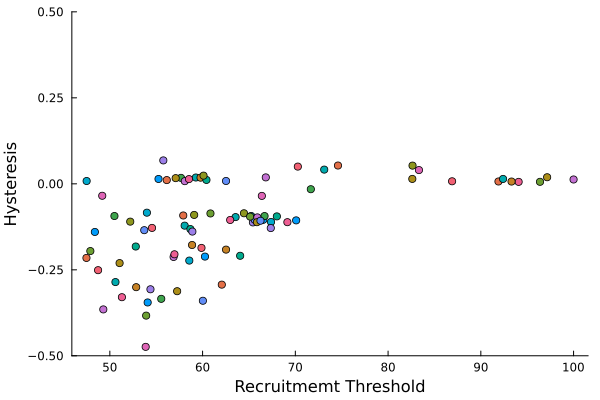

In [9]:
Plots.scatter(recr_inter_input/maximum(recr_inter_input)*100, hysteresis, grid=false,legend=false, xlabel="Recruitmemt Threshold",ylabel="Hysteresis",ylim=(-0.5, 0.5))

### Interpolation of the values to obtain a "corrected" distribution

In [79]:
# ## RELATIONSHIP BETWEEN A SIZE PARAMETER AND THE RECRUITMENT THRESHOLD PLOT 

# p = Plots.plot(layout = (1, 1))
# Plots.plot!(p[1], rs_S, recr_sim, grid=false,legend=false, xlabel="Radius S",ylabel="Force at recruitment")
# # Plots.plot!(p[2], ls_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length S",ylabel="Force at recruitment")
# # Plots.plot!(p[3], rd_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Radius D",ylabel="Force at recruitment")
# # Plots.plot!(p[4], ld_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length D",ylabel="Force at recruitment")

# display(p)

In [26]:
regressed_parameter = zeros(11, nr_s)
vars= ["rs_S","ls_S","rms_S","rd_S","ld_S","rmd_S", "max_gks_S","max_gca_S","βp","Vthca_S","Apeak_S"]

for i in 1:11 #for each of the variables we are interested in
    for j in 1:nr_s
        var_interest= vars[i]
        var_interest= eval(Meta.parse(var_interest))
        X = hcat(ones(length(var_interest)), var_interest)
        model = lm(X, recr_sim) 
        b = coef(model) 
        regressed_parameter[i,j] = (recruitment_experimental_normal[j]-b[1])/ b[2]
    end
end
regressed_parameter
JLD2.@save "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/regressed_parameter_87neurons_NOIF.jld2" regressed_parameter


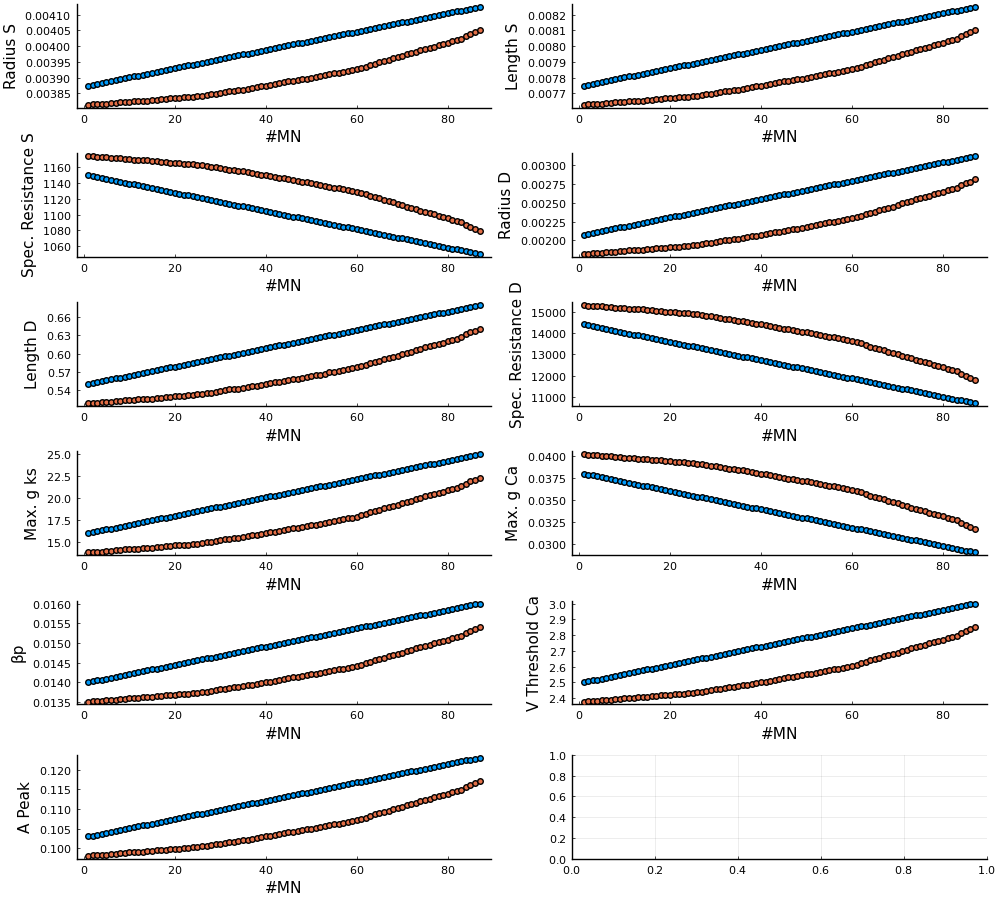

sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


In [27]:
pyplot()  

default(size=(1000, 900))

p = Plots.plot(layout = (6, 2))

percent_changes = [(regressed_parameter[i, :] .- rs_S[i]) ./ rs_S[i] * 100 for i in 1:size(regressed_parameter, 1)]


r=1:87
Plots.scatter!(p[1,1], r, rs_S, grid=false, xlabel="#MN", ylabel="Radius S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,1], r, regressed_parameter[1,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[1,2], r, ls_S, grid=false, xlabel="#MN", ylabel="Length S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,2], r, regressed_parameter[2,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,1], r, rms_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,1],r, regressed_parameter[3,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,2], r, rd_S, grid=false, xlabel="#MN", ylabel="Radius D",legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,2], r, regressed_parameter[4,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,1], r, ld_S, grid=false, xlabel="#MN", ylabel="Length D", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,1], r, regressed_parameter[5,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,2], r, rmd_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance D",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,2], r, regressed_parameter[6,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,1], r, max_gks_S, grid=false, xlabel="#MN", ylabel="Max. g ks", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,1], r, regressed_parameter[7,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,2], r, max_gca_S, grid=false, xlabel="#MN", ylabel="Max. g Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,2], r, regressed_parameter[8,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,1],r, βp, grid=false, xlabel="#MN", ylabel="βp", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,1], r, regressed_parameter[9,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,2], r, Vthca_S, grid=false, xlabel="#MN", ylabel="V Threshold Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,2], r, regressed_parameter[10,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[6,1], r, Apeak_S, grid=false, xlabel="#MN", ylabel="A Peak", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[6,1], r, regressed_parameter[11,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

# Finally, display the complete layout
display(p)


### Plot changed of the regressed parameters compared to the original parameters (that come from literature)

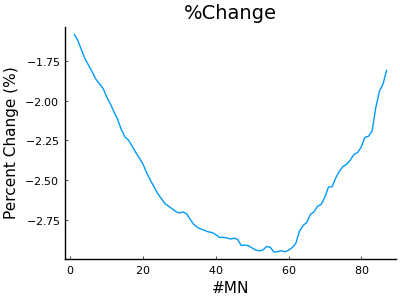

In [28]:
default(size=(400, 300))
Plots.plot(([(regressed_parameter[1, :] - rs_S) ./ rs_S * 100 for i in 1:12][1,:]), title="%Change", ylabel="Percent Change (%)", xlabel="#MN", legend=false, grid=false)  


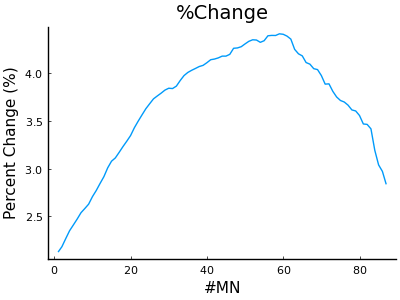

In [29]:
default(size=(400, 300))
Plots.plot(([(regressed_parameter[3, :] - rms_S) ./ rms_S * 100 for i in 1:12][1,:]), title="%Change", ylabel="Percent Change (%)", xlabel="#MN", legend=false, grid=false)  


## Computation of the rates 

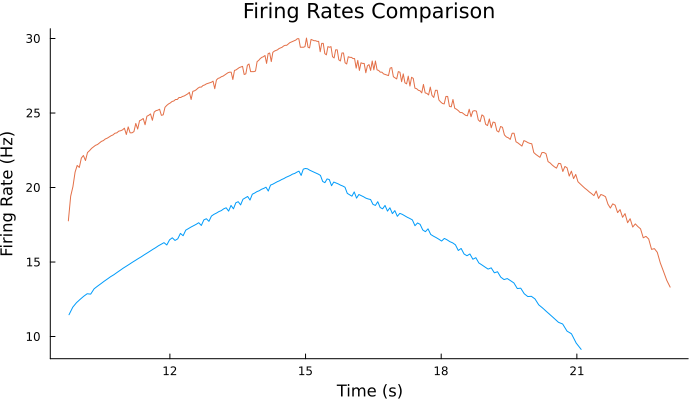

In [62]:
default(size=(700, 400))

sampling_rate = 20000 # Hz

all_timebases = []
all_rates = []

for mn in 30:31#1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], legend=false, grid=false)
    end
end

display(p)

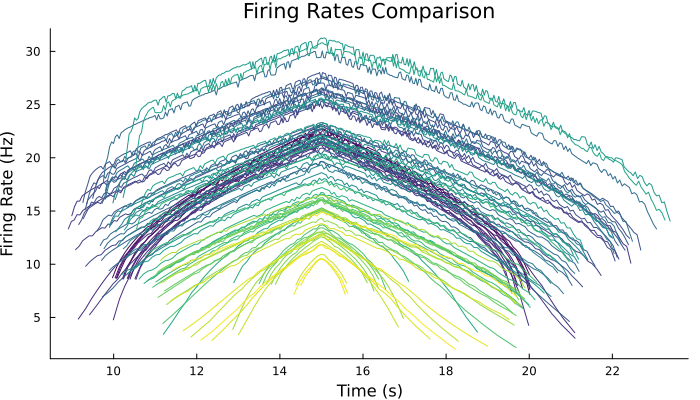

In [35]:
sampling_rate = 20000  # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

color_map = get(ColorSchemes.viridis, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], color=color_map[i], legend=false, grid=false)
    end
end

display(p)


### Plot of recruitment threshold VS. max firing rates per motoneuron - they should follow a linear decrease

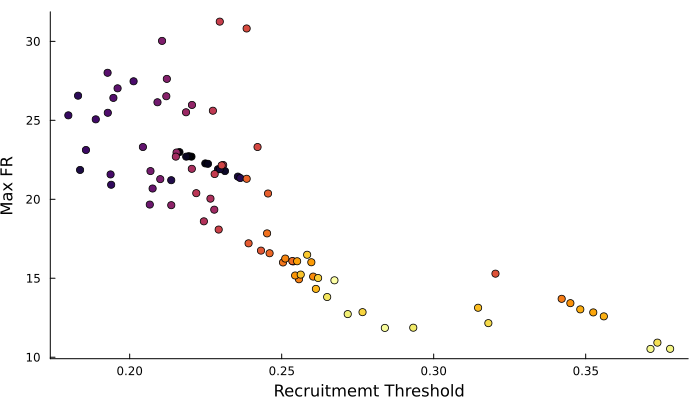

In [57]:
max_vals=zeros(1,nr_s)
color_map = get(ColorSchemes.inferno, LinRange(0, 1, size(spike_array, 1)))

p = Plots.plot(legend=false, grid=false)

for i in 1:nr_s
    max_vals[1,i]=maximum(all_rates[i])
    Plots.scatter!([recr_inter_input[i]], [max_vals[1,i]],color=color_map[i], grid=false,legend=false, xlabel="Recruitmemt Threshold",ylabel="Max FR")#,ylim=(-0.5, 0.5))
end

display(p)

## CONTROLLER

##### Find motoneurons that have the most similar recruitment thresholds

In [9]:
mn_that_is_similar = [Int[] for _ in 1:nr_s]
mn_that_has_lower_threshold= [Int[] for _ in 1:nr_s]

for i in 1:nr_s
    diff = zeros(Float64, nr_s)
    for j in 1:nr_s
        if i != j
            diff[j] = abs(recr_inter_input[i] - recr_inter_input[j])
        end
    end
        deleteat!(diff, i)
    mn_that_is_similar[i] = findall(x -> x == minimum(diff), diff)

end

println(" Motoneuron             | Similar Motoneuron (recr threshold)")
for i in 1:length(recr_inter_input)
    println(" $(i), $(recr_inter_input[i]) | $(mn_that_is_similar[i]), $(recr_inter_input[mn_that_is_similar[i]])")
end

UndefVarError: UndefVarError: recr_inter_input not defined

##### For the controller we have to take two motoneurons that have similar DR but one that is more low threshold

In [11]:
# function conv_spikes(array, pos1,pos2)

#     window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
#     hanning_window = DSP.Windows.hanning(window_samples);
#     hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

#     smoothed_spike_array1 = conv(array[pos1,:], hanning_window);# Convolve the spike arrays with the Gaussian window
#     smoothed_spike_array2 = conv(array[pos2,:], hanning_window);

#     # Because convolution extends the length of the array,let's truncate it to the original length
#     len = length(array[1,:]);
#     smoothed_spike_array1 = smoothed_spike_array1[1:len];
#     smoothed_spike_array2 = smoothed_spike_array2[1:len];

# return smoothed_spike_array1, smoothed_spike_array2
# end
# smoothed_spike_array1,smoothed_spike_array2= conv_spikes(spike_array, 1,2)

In [12]:
# dr_1_2= [smoothed_spike_array1 smoothed_spike_array2];

# x = range(0, stop=maximum(smoothed_spike_array1), length=length(smoothed_spike_array1)); #used to have a +2 at the end of the length (why?)
# y_values = LinRange(0., maximum(smoothed_spike_array1), length(smoothed_spike_array1));
# x_values = zeros(length(y_values));
# vertical_line = hcat(x_values, y_values); #this is the line that would make us achieve flexible control

# vscode kind of collapses when plotting following lines for some reason
# Plots.plot(dr_1_2[:,1],dr_1_2[:,2])
# Plots.plot!(vertical_line[:,1],vertical_line[:,2])

### Functions for the control algorithm

In [2]:
function run_sim_optim_constant_inh(MN_list,i)
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

# function run_sim_optim_constant_inh()
#     for i in 1:nr_s
#         # temp = filter_input(50,rand(Normal(0, 1),sim_length+2000))  # add some gaussian noise - optional
#         # independantnoise[i,:] = temp[1001:end-1000] * 0.25;
#         full_input[i,:] = commoninput  + independantnoise[i,:]; 
#         vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input[i,:], inh_input, MNs)      
#         spikes = spikes_from_aps(vs, i, MNs)       
#         spike_arr[i,:] = spikes
#         vs_arr[i,:] = vs
#     end
#     return spike_arr, vs_arr
# end


function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window);# Convolve the spike arrays with the Gaussian window
    smoothed_spike_array2 = conv(array2[1,:], hanning_window);

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end

    

conv_spikes_rates (generic function with 1 method)

### Init control algorithm

In [3]:
######################  S-TYPE ##########################
#########################################################
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/regressed_parameter_87neurons_NOIF.jld2" regressed_parameter
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hystprofile.jld2" γn_new

nr_s = 87

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = regressed_parameter[1,:]
ls_S = regressed_parameter[2,:] 
rms_S = regressed_parameter[3,:]
rd_S = regressed_parameter[4,:]
ld_S = regressed_parameter[5,:]
rmd_S = regressed_parameter[6,:]

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S = regressed_parameter[7,:]
max_gca_S = regressed_parameter[8,:]


# Rate constants of the kinetic processes in ms^-1
αm = 22.0; βm = 13.0
αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4
αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1
αq_S = ones(nr_s)*1.5
βq_S = ones(nr_s)*0.025
αp = 0.008
βp= regressed_parameter[9,:]
βp_S = ones(nr_s)*0.014

Vthca_S = regressed_parameter[10,:]
Apeak_S =  regressed_parameter[11,:]
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
# start_index = 8  
# values = LinRange(1.0, 0.2, nr_s - start_index + 1)
# IF = [zeros(start_index - 1); values]# EF= LinRange(0.8,1.8, nr_s);
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; 
ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 
#maximun conductances
Ge=0.6; Gi=0.5 ; 
#initial voltages
Vd0 = 0.; 
Vs0 = 0.;
#refractory period
rp=5.0; 
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]

x_values = LinRange(0, 87, nr_s);
γh= γn_new[1,:];

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp, :βp => βp_S[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm, :βm => βm, :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i],:αp => αp, :βp => βp[i],  :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;

tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.3 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);

# tr=tr_new
# @time spike_array, vs_array = run_sim();


#### Loop version of the controller

In [29]:
# Control parameters
kp = Float32(0.9)
kd = Float32(0.2)
dt = Float32(0.1)

convergence_threshold = 0.0001
convergence_count_threshold = 100000

# Initialize variables
convergence_count = [0, 0]  
previous_error_vec = zeros(2, 1) 

tr_new = copy(tr)

mn1 = 22
mn2 = 23

for iteration in 1:100
    println("Iteration: $iteration")
    commoninput = tr_new  # Needed for the run_sim() function
    
    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  # Simulate for motoneuron 1
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  # Simulate for motoneuron 2

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    println("Processing spikes")

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg

    # Compute the new trajectory that gives us flexibility
    x = range(0, stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    y_values = LinRange(0., maximum(trajectory2_controlled[:, 1]), length(trajectory2_controlled[:, 1]))
    x_values = zeros(length(y_values))
    trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control

    for i in 1:size(trajectory1, 1) - 2
        for dim in 1:2  # First column is the first MN, the low threshold one
            error = trajectory1[i, dim] - trajectory2_controlled[i, dim]
            derivative_error = (error - previous_error_vec[dim]) / dt
            control_output = kp * error + kd * derivative_error

            tr_new[i] += control_output
            previous_error_vec[dim] = error

            if abs(error) < convergence_threshold
                convergence_count[dim] += 1
            else
                convergence_count[dim] = 0
            end

            if convergence_count[dim] > convergence_count_threshold
                # println("Convergence achieved at iteration $iteration in dimension $dim.")
                breaka
            end
        end

        if all(convergence_count .> convergence_count_threshold)
            println("Overall convergence achieved at iteration $iteration.")
            break
        end
    end
end


Iteration: 1
Processing spikes
Iteration: 2
Processing spikes
Iteration: 3
Processing spikes
Iteration: 4
Processing spikes
Iteration: 5
Processing spikes
Iteration: 6
Processing spikes
Iteration: 7
Processing spikes
Iteration: 8
Processing spikes
Iteration: 9
Processing spikes
Iteration: 10
Processing spikes
Iteration: 11
Processing spikes
Iteration: 12
Processing spikes
Iteration: 13
Processing spikes
Iteration: 14
Processing spikes
Iteration: 15
Processing spikes
Iteration: 16
Processing spikes
Iteration: 17
Processing spikes
Iteration: 18
Processing spikes
Iteration: 19
Processing spikes
Iteration: 20
Processing spikes
Iteration: 21
Processing spikes
Iteration: 22
Processing spikes
Iteration: 23
Processing spikes
Iteration: 24
Processing spikes
Iteration: 25
Processing spikes
Iteration: 26
Processing spikes
Iteration: 27
Processing spikes
Iteration: 28
Processing spikes
Iteration: 29
Processing spikes
Iteration: 30
Processing spikes
Iteration: 31
Processing spikes
Iteration: 32
Pro

In [68]:
# Control parameters
kp = Float32(1.5)  # Example of increasing the proportional gain  #0.9
kd = Float32(0.5)  # Example of increasing the derivative gain #0.2
dt = Float32(0.1) 

convergence_threshold = 0.0001
convergence_count_threshold = 100000

# Initialize variables
convergence_count = 0
previous_error = 0.0
combined_error_threshold = 0.0001

tr_new = copy(tr)

mn1 = 22
mn2 = 23

for iteration in 1:1
    println("Iteration: $iteration")
    commoninput = tr_new  # Needed for the run_sim() function
    
    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  # Simulate for motoneuron 1
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  # Simulate for motoneuron 2

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    println("Processing spikes")

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg

    # Compute the new trajectory that gives us flexibility
    x = range(0, stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    y_values = range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    x_values = zeros(length(y_values))
    trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control

    for i in 1:size(trajectory1, 1) - 2
        # Compute combined error for both dimensions
        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        combined_error = (error1 + error2) / 2.0
        derivative_error = (combined_error - previous_error) / dt
        control_output = kp * combined_error + kd * derivative_error

        tr_new[i] += control_output  # Apply the same control output to the control signal
        previous_error = combined_error

        if abs(combined_error) < combined_error_threshold
            convergence_count += 1
        else
            convergence_count = 0
        end

        if convergence_count > convergence_count_threshold
            println("Overall convergence achieved at iteration $iteration.")
            break
        end
    end

    if convergence_count > convergence_count_threshold
        break
    end
end


In [5]:
# Control parameters
kp = 1.5  # Proportional gain
kd = 0.5  # Derivative gain
ki = 0.1  # Integral gain
dt = 0.1 

convergence_threshold = 0.0001
convergence_count_threshold = 100000

# Initialize variables
convergence_count = 0
previous_error1 = 0.0
previous_error2 = 0.0
integral_error1 = 0.0
integral_error2 = 0.0
combined_error_threshold = 0.0001

tr_new = copy(tr)  # Ensure tr_new is properly initialized
mn1 = 22
mn2 = 23

trajectory2_controlled= zeros(1,2)

for iteration in 1:10  # Use a smaller number for the initial test
    println("Iteration: $iteration")
    commoninput = tr_new  # Needed for the run_sim() function
    
    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  # Simulate for motoneuron 1
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  # Simulate for motoneuron 2

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    println("Processing spikes")

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg

    # Define the desired trajectory (vertical line at x=0 along the y-axis)
    y_values = range(0., stop=maximum(trajectory2_controlled[:, 2]), length=length(trajectory2_controlled[:, 2]))
    x_values = zeros(length(y_values))
    trajectory1 = hcat(x_values, y_values)  # Desired trajectory

    for i in 1:size(trajectory1, 1) - 2
        # Compute error for each dimension
        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        
        # Update integral errors
        integral_error1 += error1 * dt
        integral_error2 += error2 * dt
        
        # Compute derivative errors
        derivative_error1 = (error1 - previous_error1) / dt
        derivative_error2 = (error2 - previous_error2) / dt
        
        # Compute control outputs using PID formula
        control_output1 = kp * error1 + kd * derivative_error1 + ki * integral_error1
        control_output2 = kp * error2 + kd * derivative_error2 + ki * integral_error2

        # Compute the combined control output
        combined_control_output = (control_output1 + control_output2) / 2.0

        # Apply the control output to the control signal
        if i <= length(tr_new)
            tr_new[i] += combined_control_output
        end

        previous_error1 = error1
        previous_error2 = error2

        # # Print debug information for errors and control output
        # println("Index: $i, Error1: $error1, Error2: $error2, Control Output: $combined_control_output, Integral Error1: $integral_error1, Integral Error2: $integral_error2")
        # println("Updated tr_new[$i]: ", tr_new[i])

        if abs(error1) < combined_error_threshold && abs(error2) < combined_error_threshold
            convergence_count += 1
        else
            convergence_count = 0
        end

        if convergence_count > convergence_count_threshold
            println("Overall convergence achieved at iteration $iteration.")
            break
        end
    end

    # Print the controlled trajectory for debugging
    # println("trajectory2_controlled after iteration $iteration:")
    # println(trajectory2_controlled)

    if convergence_count > convergence_count_threshold
        break
    end
end

# Print the final controlled trajectory
println("Final trajectory2_controlled:")
println(trajectory2_controlled)


Iteration: 1
Processing spikes
Iteration: 2
Processing spikes
Iteration: 3
Processing spikes
Iteration: 4
Processing spikes
Iteration: 5
Processing spikes
Iteration: 6
Processing spikes
Iteration: 7
Processing spikes
Overall convergence achieved at iteration 7.
Final trajectory2_controlled:
[0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0.0; 0.0 0

In [26]:
commoninput = tr_new; # needed for the run_sim() function
spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1],mn1)  # Simulate for motoneuron 1
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2],mn2)  # Simulate for motoneuron 2


#### convolution of the spikes to get rates for  the 2 motoneurons so they have the same length
smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1,spike_arr_mn2)  
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg

    # Compute the new trajectory that gives us flexibility
x = range(0, stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
y_values = LinRange(0., maximum(trajectory2_controlled[:, 1]), length(trajectory2_controlled[:, 1]))
x_values = zeros(length(y_values))
trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control


30000×2 Matrix{Float64}:
 0.0  0.0
 0.0  4.13666e-8
 0.0  8.27333e-8
 0.0  1.241e-7
 0.0  1.65467e-7
 0.0  2.06833e-7
 0.0  2.482e-7
 0.0  2.89567e-7
 0.0  3.30933e-7
 0.0  3.723e-7
 ⋮    
 0.0  0.00124063
 0.0  0.00124067
 0.0  0.00124071
 0.0  0.00124075
 0.0  0.00124079
 0.0  0.00124083
 0.0  0.00124088
 0.0  0.00124092
 0.0  0.00124096

In [10]:
tr_new

30000-element Vector{Float64}:
 -0.21903249848376705
 -0.20715054319455592
 -0.2071504227839271
 -0.20715030158112302
 -0.20715017958614382
 -0.2071500567989894
 -0.2071499332196598
 -0.20714980884815498
 -0.207149683684475
 -0.20714955772861987
  ⋮
 -0.20372950928810168
 -0.2037056315435328
 -0.20368175300678878
 -0.20365787367786956
 -0.20363399355677514
 -0.20361011264350554
 -0.20358623093806075
 -0.1
 -0.1

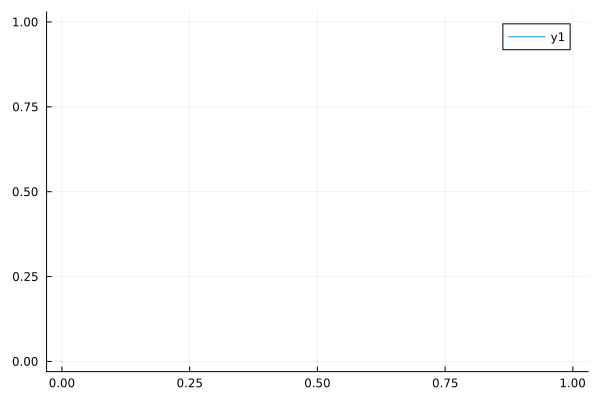

In [6]:
x = range(0, stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
y_values = LinRange(0., maximum(trajectory2_controlled[:, 1]), length(trajectory2_controlled[:, 1]))
x_values = zeros(length(y_values))
trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control

Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

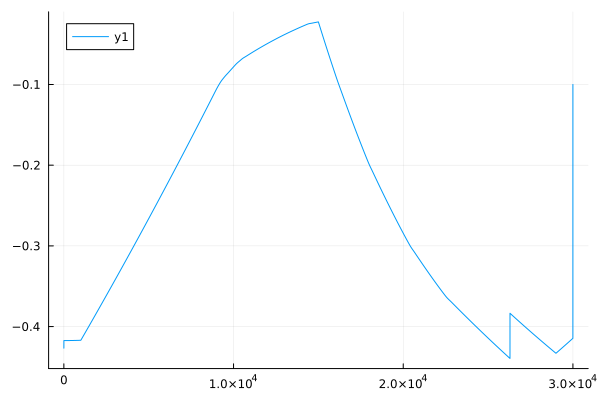

In [7]:
Plots.plot(1:30000,tr_new)

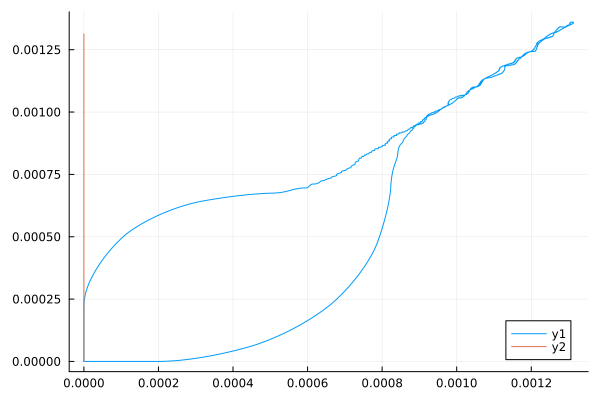

In [19]:
# x = range(0, stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
# y_values = LinRange(0., maximum(trajectory2_controlled[:, 1]), length(trajectory2_controlled[:, 1]))
# x_values = zeros(length(y_values))
# trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control


Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,2])  # Controlled trajectory from neurons)
Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)